# A13 — Problem B Dense+CNN: MoveNet Good vs Bad Exercise Classification

This notebook solves Lab Assignment 13 for **Problem B** using a classifier with **CNN layers**.

- Input: MoveNet 2D frame sequences — 13 joints × 2 dims = 26 features × c frames
- Model: 1D Conv layers (CNN) over the temporal axis → Dense (Linear) classification head
- Task: binary classification — *good* vs *bad* exercise


### Imports, settings, paths

In [3]:
from pathlib import Path
import os
import random
import warnings
import json
import copy
import joblib
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, train_test_split
try:
    from sklearn.model_selection import StratifiedGroupKFold
    HAS_STRATIFIED_GROUP_KFOLD = True
except ImportError:
    HAS_STRATIFIED_GROUP_KFOLD = False

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEQ_LEN          = 10
N_SPLITS         = 10
VALIDATION_SPLIT = 0.10

EPOCHS        = 120
PATIENCE      = 15
BATCH_SIZE    = 16
LEARNING_RATE = 1e-3
THRESHOLD     = 0.50

NUM_WORKERS = 0
PIN_MEMORY  = torch.cuda.is_available()

MOVENET_GOOD_BAD_DIR = Path("../../../data/processed/Good_vs_Bad_movenet/csv_output")
CUT_BOUNDS_CSV       = Path("../../A11/Kim/reporting/results/a11_problem_b_all_boundary_table.csv")

output_dir   = Path("reporting/results")
output_dir.mkdir(parents=True, exist_ok=True)
artifact_dir = Path("reporting/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("MOVENET_GOOD_BAD_DIR:", MOVENET_GOOD_BAD_DIR)
print("CUT_BOUNDS_CSV:", CUT_BOUNDS_CSV)


DEVICE: cpu
MOVENET_GOOD_BAD_DIR: ../../../data/processed/Good_vs_Bad_movenet/csv_output
CUT_BOUNDS_CSV: ../../A11/Kim/reporting/results/a11_problem_b_all_boundary_table.csv


### MLFlow setup

In [4]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A13_problem_B_movenet_good_bad_dense_cnn"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()


MLFLOW_TRACKING_URI = https://172.27.62.170:5001/


KeyboardInterrupt: 

### MoveNet loading helpers

In [ ]:
FRAME_COL_CANDIDATES = [
    "frame_index", "frame", "frame_id", "FrameNo", "frame_no", "image_id",
]

MOVENET_TO_ASSIGNMENT = {
    "nose":          "head",
    "left_shoulder": "left_shoulder",
    "left_elbow":    "left_elbow",
    "right_shoulder":"right_shoulder",
    "right_elbow":   "right_elbow",
    "left_wrist":    "left_hand",
    "right_wrist":   "right_hand",
    "left_hip":      "left_hip",
    "right_hip":     "right_hip",
    "left_knee":     "left_knee",
    "right_knee":    "right_knee",
    "left_ankle":    "left_foot",
    "right_ankle":   "right_foot",
}

JOINTS_13 = list(MOVENET_TO_ASSIGNMENT.values())

COORD_COLS = []
for joint in JOINTS_13:
    COORD_COLS.extend([f"{joint}_x", f"{joint}_y"])


def strip_columns(df):
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df


def find_frame_col(df):
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col
    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def load_movenet_as_assignment_df(csv_path):
    df = pd.read_csv(csv_path)
    df = strip_columns(df)
    frame_col = find_frame_col(df)

    out = pd.DataFrame()
    out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)
    if "timestamp_ms" in df.columns:
        out["timestamp_ms"] = df["timestamp_ms"]

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y", "score"]:
            src = f"{movenet_joint}_{suffix}"
            dst = f"{assignment_joint}_{suffix}"
            if src not in df.columns:
                raise ValueError(f"Missing column '{src}' in {csv_path}")
            out[dst] = pd.to_numeric(df[src], errors="coerce")

    return out.sort_values("frame_index").reset_index(drop=True)


def sequence_label_from_name(sequence_id):
    stem = Path(sequence_id).stem
    if stem == "A1" or stem.startswith("G"):
        return 1
    if stem.startswith("W"):
        return 0
    raise ValueError(f"Cannot infer label from: {sequence_id}")


def stem_base(path):
    return Path(path).stem


### Start/stop loading helpers

In [ ]:
def load_cut_bounds_table(cut_bounds_csv):
    if not cut_bounds_csv.exists():
        print("No cut bounds CSV found. Using full sequences as fallback.")
        return None

    bounds_df = pd.read_csv(cut_bounds_csv)
    bounds_df.columns = [c.strip() for c in bounds_df.columns]

    if {"start_frame", "stop_frame"}.issubset(bounds_df.columns):
        pass
    elif {"pred_start", "pred_stop"}.issubset(bounds_df.columns):
        bounds_df = bounds_df.rename(columns={"pred_start": "start_frame", "pred_stop": "stop_frame"})
    else:
        raise ValueError("CUT_BOUNDS_CSV must contain start_frame/stop_frame or pred_start/pred_stop.")

    bounds_df["sequence_id"] = bounds_df["sequence_id"].astype(str)
    bounds_df["start_frame"] = pd.to_numeric(bounds_df["start_frame"], errors="coerce")
    bounds_df["stop_frame"]  = pd.to_numeric(bounds_df["stop_frame"],  errors="coerce")
    bounds_df = bounds_df.dropna(subset=["start_frame", "stop_frame"]).copy()
    bounds_df["start_frame"] = bounds_df["start_frame"].astype(int)
    bounds_df["stop_frame"]  = bounds_df["stop_frame"].astype(int)
    return bounds_df[["sequence_id", "start_frame", "stop_frame"]]


def get_sequence_bounds(sequence_id, df, bounds_lookup):
    if bounds_lookup is not None and sequence_id in bounds_lookup:
        s, e = bounds_lookup[sequence_id]
        return int(s), int(e), "cut_bounds_csv"
    return int(df["frame_index"].min()), int(df["frame_index"].max()), "full_sequence_fallback"


def cut_sequence(df, start_frame, stop_frame):
    out = df[(df["frame_index"] >= start_frame) & (df["frame_index"] <= stop_frame)].copy()
    return out.sort_values("frame_index").reset_index(drop=True)


In [ ]:
candidate_paths = [
    Path("../../A11/Kim/reporting/results/a11_problem_b_all_boundary_table.csv"),
    Path("../../A11/Kim/reporting/results/a11_problem_b_final_sequence_eval.csv"),
    Path("../../A11/Kim/reporting/results/a11_problem_b_sequence_eval.csv"),
]
for p in candidate_paths:
    print(p, "exists:", p.exists())
    if p.exists():
        df_tmp = pd.read_csv(p)
        print("  shape:", df_tmp.shape, "  columns:", df_tmp.columns.tolist())


../../A11/Kim/reporting/results/a11_problem_b_all_boundary_table.csv exists: True
  shape: (179, 11)   columns: ['sequence_id', 'true_start', 'true_stop', 'pred_start', 'pred_stop', 'start_error_frames', 'stop_error_frames', 'abs_start_error_frames', 'abs_stop_error_frames', 'detected_segment', 'total_abs_error']
../../A11/Kim/reporting/results/a11_problem_b_final_sequence_eval.csv exists: True
  shape: (18, 10)   columns: ['sequence_id', 'true_start', 'true_stop', 'pred_start', 'pred_stop', 'start_error_frames', 'stop_error_frames', 'abs_start_error_frames', 'abs_stop_error_frames', 'detected_segment']
../../A11/Kim/reporting/results/a11_problem_b_sequence_eval.csv exists: True
  shape: (18, 15)   columns: ['sequence_id', 'true_start', 'true_stop', 'pred_start', 'pred_stop', 'start_error_frames', 'stop_error_frames', 'abs_start_error_frames', 'abs_stop_error_frames', 'detected_segment', 'n_test_windows', 'n_true_positive_windows', 'n_pred_positive_windows', 'mean_prob', 'max_prob']


### Load A11 start/stop model from MLFlow

In [ ]:
A11_EXPERIMENT_NAME = "A11_movenet_exercise_frame_classification_B"
A11_RUN_NAME        = "problem_b_final_champion_test_eval"

experiment = mlflow.get_experiment_by_name(A11_EXPERIMENT_NAME)
if experiment is None:
    raise RuntimeError(f"Could not find MLflow experiment: {A11_EXPERIMENT_NAME}")

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string=f"tags.mlflow.runName = '{A11_RUN_NAME}'",
    order_by=["start_time DESC"],
    max_results=1,
)
if runs.empty:
    raise RuntimeError(f"Could not find run '{A11_RUN_NAME}' in '{A11_EXPERIMENT_NAME}'.")

a11_run_id    = runs.iloc[0]["run_id"]
A11_MODEL_URI = f"runs:/{a11_run_id}/model"
print("A11 model URI:", A11_MODEL_URI)

a11_cut_model = mlflow.pyfunc.load_model(A11_MODEL_URI)
print("Loaded A11 wrapped start/stop model.")


A11 model URI: runs:/8ed7e14daa304f3aa9537052c9bd7222/model
Loaded A11 wrapped start/stop model.


### Use A11 model to create Good/Bad cut bounds

In [ ]:
def predict_cut_bounds_for_good_bad_csvs(movenet_dir, cut_model, output_csv):
    rows = []
    csv_files = sorted(movenet_dir.glob("*.csv"))
    print("Found MoveNet Good/Bad CSV files:", len(csv_files))

    for csv_path in csv_files:
        sequence_id = csv_path.stem
        try:
            _ = sequence_label_from_name(sequence_id)
        except ValueError:
            continue

        raw_df = pd.read_csv(csv_path)
        raw_df.columns = [str(c).strip() for c in raw_df.columns]
        raw_df["sequence_id"] = sequence_id

        try:
            pred_df = cut_model.predict(raw_df)
            if pred_df.empty:
                rows.append({"sequence_id": sequence_id, "pred_start": np.nan,
                             "pred_stop": np.nan, "cut_status": "empty_prediction"})
                continue
            rows.append({
                "sequence_id": sequence_id,
                "pred_start":  pred_df["pred_start"].iloc[0],
                "pred_stop":   pred_df["pred_stop"].iloc[0],
                "cut_status":  "ok",
            })
        except Exception as e:
            rows.append({"sequence_id": sequence_id, "pred_start": np.nan,
                         "pred_stop": np.nan, "cut_status": f"error: {e}"})

    result_df = pd.DataFrame(rows)
    result_df.to_csv(output_csv, index=False)
    print("Saved cut bounds to:", output_csv)
    return result_df


GOOD_BAD_CUT_BOUNDS_CSV = output_dir / "a13_good_bad_cut_bounds.csv"

if not GOOD_BAD_CUT_BOUNDS_CSV.exists() and MOVENET_GOOD_BAD_DIR.exists():
    cut_bounds_df = predict_cut_bounds_for_good_bad_csvs(
        movenet_dir=MOVENET_GOOD_BAD_DIR,
        cut_model=a11_cut_model,
        output_csv=GOOD_BAD_CUT_BOUNDS_CSV,
    )
    display(cut_bounds_df.head())
else:
    print("Using existing cut bounds:", GOOD_BAD_CUT_BOUNDS_CSV)


Using existing cut bounds: reporting/results/a13_good_bad_cut_bounds.csv


In [ ]:
CUT_BOUNDS_CSV = GOOD_BAD_CUT_BOUNDS_CSV
print("Using Good/Bad cut bounds:", CUT_BOUNDS_CSV)
print("Exists:", CUT_BOUNDS_CSV.exists())


Using Good/Bad cut bounds: reporting/results/a13_good_bad_cut_bounds.csv
Exists: True


### Load all MoveNet Good/Bad sequences

In [ ]:
def load_good_bad_sequences(movenet_dir, cut_bounds_csv, min_cut_frames=SEQ_LEN):
    if not movenet_dir.exists():
        raise FileNotFoundError(f"MoveNet directory not found: {movenet_dir}")

    cut_bounds_df = load_cut_bounds_table(cut_bounds_csv)
    bounds_lookup = None
    if cut_bounds_df is not None:
        bounds_lookup = {
            row["sequence_id"]: (row["start_frame"], row["stop_frame"])
            for _, row in cut_bounds_df.iterrows()
        }

    rows = []
    sequence_dfs = {}
    csv_files = sorted(movenet_dir.glob("*.csv"))
    print("Found MoveNet CSV files:", len(csv_files))

    for csv_path in csv_files:
        sequence_id = stem_base(csv_path)
        try:
            label = sequence_label_from_name(sequence_id)
        except ValueError:
            continue

        raw_df = load_movenet_as_assignment_df(csv_path)
        start_frame, stop_frame, cut_source = get_sequence_bounds(sequence_id, raw_df, bounds_lookup)
        cut_df = cut_sequence(raw_df, start_frame, stop_frame)
        kept = len(cut_df) >= min_cut_frames
        if kept:
            sequence_dfs[sequence_id] = cut_df

        rows.append({
            "sequence_id":   sequence_id,
            "path":          str(csv_path),
            "label":         label,
            "start_frame":   start_frame,
            "stop_frame":    stop_frame,
            "cut_source":    cut_source,
            "n_frames_raw":  len(raw_df),
            "n_frames_cut":  len(cut_df),
            "kept":          kept,
            "reason":        "ok" if kept else "too_short_after_cut",
        })

    catalog_df = pd.DataFrame(rows)
    if catalog_df.empty:
        raise RuntimeError("No valid MoveNet good/bad sequences were loaded.")
    return catalog_df, sequence_dfs


catalog_df, sequence_dfs = load_good_bad_sequences(
    movenet_dir=MOVENET_GOOD_BAD_DIR,
    cut_bounds_csv=CUT_BOUNDS_CSV,
    min_cut_frames=SEQ_LEN,
)

print("Loaded catalog:")
display(catalog_df.head())
print("Kept sequences:", int(catalog_df["kept"].sum()))
print("Dropped sequences:", int((~catalog_df["kept"]).sum()))
print("\nLabel distribution (kept):")
print(catalog_df[catalog_df["kept"]]["label"].value_counts())


Found MoveNet CSV files: 114
Loaded catalog:


,sequence_id,path,label,start_frame,stop_frame,cut_source,n_frames_raw,n_frames_cut,kept,reason
0,A1,../../../data/processed/Good_vs_Bad_movenet/cs...,1,75,172,cut_bounds_csv,229,98,True,ok
1,G01,../../../data/processed/Good_vs_Bad_movenet/cs...,1,68,159,cut_bounds_csv,254,92,True,ok
2,G02,../../../data/processed/Good_vs_Bad_movenet/cs...,1,134,224,cut_bounds_csv,314,91,True,ok
3,G03,../../../data/processed/Good_vs_Bad_movenet/cs...,1,81,161,cut_bounds_csv,250,81,True,ok
4,G04,../../../data/processed/Good_vs_Bad_movenet/cs...,1,41,153,cut_bounds_csv,219,113,True,ok


Kept sequences: 112
Dropped sequences: 2

Label distribution (kept):
label
1    71
0    41
Name: count, dtype: int64


### Feature engineering after min-max normalization

In [ ]:
SELECTED_DISTANCE_PAIRS = [
    ("left_shoulder",  "right_shoulder"),
    ("left_hip",       "right_hip"),
    ("left_shoulder",  "left_elbow"),
    ("left_elbow",     "left_hand"),
    ("right_shoulder", "right_elbow"),
    ("right_elbow",    "right_hand"),
    ("left_hip",       "left_knee"),
    ("left_knee",      "left_foot"),
    ("right_hip",      "right_knee"),
    ("right_knee",     "right_foot"),
    ("left_shoulder",  "left_hip"),
    ("right_shoulder", "right_hip"),
]

SELECTED_ANGLE_TRIPLES = [
    ("left_shoulder",  "left_elbow",  "left_hand"),
    ("right_shoulder", "right_elbow", "right_hand"),
    ("left_hip",       "left_knee",   "left_foot"),
    ("right_hip",      "right_knee",  "right_foot"),
    ("left_shoulder",  "left_hip",    "left_knee"),
    ("right_shoulder", "right_hip",   "right_knee"),
]


def add_selected_distances(df):
    out = df.copy()
    for a, b in SELECTED_DISTANCE_PAIRS:
        dx = out[f"{a}_x"] - out[f"{b}_x"]
        dy = out[f"{a}_y"] - out[f"{b}_y"]
        out[f"dist_{a}_{b}"] = np.sqrt(dx**2 + dy**2)
    return out


def calculate_angle(a, b, c):
    ba = a - b
    bc = c - b
    dot  = np.sum(ba * bc, axis=1)
    denom = np.linalg.norm(ba, axis=1) * np.linalg.norm(bc, axis=1)
    denom = np.where(denom == 0, np.nan, denom)
    return np.arccos(np.clip(dot / denom, -1.0, 1.0))


def add_selected_angles(df):
    out = df.copy()
    for a, b, c in SELECTED_ANGLE_TRIPLES:
        out[f"angle_{a}_{b}_{c}"] = calculate_angle(
            out[[f"{a}_x", f"{a}_y"]].to_numpy(),
            out[[f"{b}_x", f"{b}_y"]].to_numpy(),
            out[[f"{c}_x", f"{c}_y"]].to_numpy(),
        )
    return out


def get_feature_columns(feature_set):
    if feature_set == "coords":
        return COORD_COLS
    if feature_set == "coords_distances":
        return COORD_COLS + [f"dist_{a}_{b}" for a, b in SELECTED_DISTANCE_PAIRS]
    if feature_set == "coords_distances_angles":
        return (COORD_COLS
                + [f"dist_{a}_{b}" for a, b in SELECTED_DISTANCE_PAIRS]
                + [f"angle_{a}_{b}_{c}" for a, b, c in SELECTED_ANGLE_TRIPLES])
    raise ValueError(f"Unknown feature_set: {feature_set}")


def apply_feature_engineering(norm_df, feature_set):
    out = norm_df.copy()
    if feature_set in ["coords_distances", "coords_distances_angles"]:
        out = add_selected_distances(out)
    if feature_set == "coords_distances_angles":
        out = add_selected_angles(out)
    return out.reset_index(drop=True)


### Fixed length sampling and fold normalization

In [ ]:
def sample_fixed_length(df, seq_len):
    if len(df) < seq_len:
        raise ValueError(f"Sequence has {len(df)} frames, need seq_len={seq_len}.")
    indices = np.round(np.linspace(0, len(df) - 1, seq_len)).astype(int)
    return df.iloc[indices].copy().reset_index(drop=True)


def fit_minmax_scaler_on_sequences(sequence_ids, sequence_dfs):
    frames = [sequence_dfs[sid][COORD_COLS] for sid in sequence_ids]
    scaler = MinMaxScaler()
    scaler.fit(pd.concat(frames, ignore_index=True))
    return scaler


def normalize_sequence_df(df, scaler):
    out = df.copy()
    out[COORD_COLS] = scaler.transform(out[COORD_COLS])
    return out


def sequence_to_cnn_matrix(df, scaler, seq_len, feature_set):
    """
    Returns a (n_features, seq_len) matrix for the CNN.
    Features are treated as channels; frames are the temporal axis.
    """
    norm_df    = normalize_sequence_df(df, scaler)
    sampled_df = sample_fixed_length(norm_df, seq_len)
    feat_df    = apply_feature_engineering(sampled_df, feature_set)
    values     = feat_df[get_feature_columns(feature_set)].to_numpy(dtype=np.float32)
    return values.T  # (n_features, seq_len)


def build_xy_for_sequence_ids(sequence_ids, sequence_dfs, labels_lookup, scaler, seq_len, feature_set):
    X_rows, y_rows, ids = [], [], []
    for sid in sequence_ids:
        X_rows.append(sequence_to_cnn_matrix(sequence_dfs[sid], scaler, seq_len, feature_set))
        y_rows.append(labels_lookup[sid])
        ids.append(sid)
    return np.stack(X_rows).astype(np.float32), np.array(y_rows, dtype=np.float32), ids


### Dense + CNN model

Architecture:
- Input: `(batch, n_features, seq_len)` — joints/features are channels, frames are the temporal axis
- **CNN layers**: `Conv1d` → `BatchNorm1d` → `ReLU` (one or more blocks, configurable stride/padding)
- **Pooling**: `AdaptiveAvgPool1d(1)` — collapses the temporal dimension regardless of stride
- **Dense layers**: `Linear` → `ReLU` → `Linear(1)` — classification head

**Parameter budget**: the Dense baseline uses ~10,000 params; the CNN model must stay at most
20% × 10,000 = **2,000 parameters** (soft constraint from the assignment).

In [ ]:
class CNNSequenceDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        # X shape: (N, n_features, seq_len)
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class DenseCNNClassifier(nn.Module):
    """
    Classifier combining CNN and Dense layers.

    CNN layers extract local temporal patterns from the joint coordinate sequence.
    Dense (Linear) layers map the pooled CNN features to a binary output.

    Parameter budget: <= ~2,000 (at most 20% of the Dense baseline ~10,000).
    """
    def __init__(
        self,
        n_features: int,
        seq_len: int,
        conv_channels: tuple = (16,),
        kernel_size: int = 3,
        stride: int = 1,
        dense_dims: tuple = (8,),
        dropout: float = 0.20,
    ):
        super().__init__()

        # CNN part — stride/padding are configurable per the assignment requirement
        conv_layers = []
        in_ch = n_features
        for out_ch in conv_channels:
            padding = kernel_size // 2 if stride == 1 else kernel_size // 2
            conv_layers += [
                nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size,
                          stride=stride, padding=padding),
                nn.BatchNorm1d(out_ch),
                nn.ReLU(),
            ]
            if dropout > 0:
                conv_layers.append(nn.Dropout(dropout))
            in_ch = out_ch

        self.cnn  = nn.Sequential(*conv_layers)
        self.pool = nn.AdaptiveAvgPool1d(1)  # handles any temporal size after strided convs

        # Dense part
        dense_layers = []
        prev_dim = in_ch
        for h in dense_dims:
            dense_layers += [nn.Linear(prev_dim, h), nn.ReLU()]
            if dropout > 0:
                dense_layers.append(nn.Dropout(dropout))
            prev_dim = h
        dense_layers.append(nn.Linear(prev_dim, 1))

        self.dense = nn.Sequential(*dense_layers)

    def forward(self, x):
        # x: (batch, n_features, seq_len)
        x = self.cnn(x)              # (batch, last_ch, reduced_seq_len)
        x = self.pool(x).squeeze(-1)  # (batch, last_ch)
        return self.dense(x).squeeze(-1)


def count_trainable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def estimate_params(n_features, conv_channels, kernel_size, dense_dims):
    """Quick parameter estimate before building the model."""
    total, in_ch = 0, n_features
    for out_ch in conv_channels:
        total += in_ch * out_ch * kernel_size + out_ch  # Conv1d
        total += 2 * out_ch                              # BatchNorm1d
        in_ch = out_ch
    prev = in_ch
    for h in dense_dims:
        total += prev * h + h
        prev = h
    total += prev + 1  # final Linear(..., 1)
    return total


# Sanity check all planned configs against the 2,000-param budget
print(f"{'Config':<40} {'Est. params':>12}  {'OK?':>6}")
print("-" * 62)
for name, n_feat, conv_ch, k, dense_d in [
    ("cnn_16_k3_fc8",         26, (16,),   3, (8,)),
    ("cnn_8_16_k3",           26, (8,16),  3, ()),
    ("cnn_8_k3_fc8",          26, (8,),    3, (8,)),
    ("cnn_4_8_k3_fc4",        26, (4,8),   3, (4,)),
    ("cnn_8_k3_stride2_fc8",  26, (8,),    3, (8,)),
    ("cnn_16_k3_dist",        38, (16,),   3, ()),
    ("cnn_8_k3_dist",         38, (8,),    3, ()),
]:
    p = estimate_params(n_feat, conv_ch, k, dense_d)
    ok = "YES" if p <= 2000 else "OVER"
    print(f"  {name:<38} {p:>12}  {ok:>6}")


Config                                    Est. params     OK?
--------------------------------------------------------------
  cnn_16_k3_fc8                                  1441     YES
  cnn_8_16_k3                                    1097     YES
  cnn_8_k3_fc8                                    729     YES
  cnn_4_8_k3_fc4                                  485     YES
  cnn_8_k3_stride2_fc8                            729     YES
  cnn_16_k3_dist                                 1889     YES
  cnn_8_k3_dist                                   945     YES


### Dataset, model, training helpers

In [ ]:
def make_loader(X, y, batch_size, shuffle):
    dataset = CNNSequenceDataset(X, y)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)


def evaluate_model(model, loader, threshold=THRESHOLD):
    model.eval()
    all_probs, all_preds, all_true = [], [], []
    total_loss, n_samples = 0.0, 0
    criterion = nn.BCEWithLogitsLoss()

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(X_batch)
            loss   = criterion(logits, y_batch)

            probs = torch.sigmoid(logits).detach().cpu().numpy()
            preds = (probs >= threshold).astype(int)

            all_probs.extend(probs.tolist())
            all_preds.extend(preds.tolist())
            all_true.extend(y_batch.detach().cpu().numpy().astype(int).tolist())
            total_loss += loss.item() * len(X_batch)
            n_samples  += len(X_batch)

    y_true = np.array(all_true)
    y_pred = np.array(all_preds)
    y_prob = np.array(all_probs)
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else np.nan

    return {
        "loss":      total_loss / max(n_samples, 1),
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred, zero_division=0),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "auc":       auc,
        "tp": int(((y_true == 1) & (y_pred == 1)).sum()),
        "fp": int(((y_true == 0) & (y_pred == 1)).sum()),
        "tn": int(((y_true == 0) & (y_pred == 0)).sum()),
        "fn": int(((y_true == 1) & (y_pred == 0)).sum()),
        "y_true": y_true, "y_pred": y_pred, "y_prob": y_prob,
    }


def train_one_model(model, train_loader, val_loader, learning_rate, epochs, patience):
    criterion        = nn.BCEWithLogitsLoss()
    optimizer        = torch.optim.Adam(model.parameters(), lr=learning_rate)
    best_state       = copy.deepcopy(model.state_dict())
    best_val_loss    = np.inf
    best_epoch       = -1
    patience_counter = 0
    history          = []

    for epoch in range(epochs):
        model.train()
        train_loss_sum, n_train = 0.0, 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(X_batch)
            n_train        += len(X_batch)

        val_metrics = evaluate_model(model, val_loader)

        history.append({
            "epoch":        epoch + 1,
            "train_loss":   train_loss_sum / max(n_train, 1),
            "val_loss":     val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_f1":       val_metrics["f1"],
            "val_auc":      val_metrics["auc"],
        })

        if val_metrics["loss"] < best_val_loss:
            best_val_loss    = val_metrics["loss"]
            best_epoch       = epoch + 1
            best_state       = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    model.load_state_dict(best_state)
    summary = {
        "best_val_loss": float(best_val_loss),
        "best_epoch":    int(best_epoch),
        "epochs_ran":    len(history),
    }
    return model, pd.DataFrame(history), summary


### Augmentation helpers for final champion only

In [ ]:
def transform_coords_2d(df, mirror_x=False, scale_x=1.0, scale_y=1.0, rotation_degrees=0.0):
    out   = df.copy()
    theta = np.deg2rad(rotation_degrees)
    R     = np.array([[np.cos(theta), -np.sin(theta)],
                      [np.sin(theta),  np.cos(theta)]])
    for joint in JOINTS_13:
        xy = out[[f"{joint}_x", f"{joint}_y"]].to_numpy(dtype=np.float32) - 0.5
        if mirror_x:
            xy[:, 0] = -xy[:, 0]
        xy[:, 0] *= scale_x
        xy[:, 1] *= scale_y
        xy = xy @ R.T + 0.5
        out[f"{joint}_x"] = xy[:, 0]
        out[f"{joint}_y"] = xy[:, 1]
    return out


def make_max_augmentation_versions(norm_df):
    versions = [("original", norm_df)]
    steps = [
        ("mirror_x",     lambda d: transform_coords_2d(d, mirror_x=True)),
        ("scale_x_1_05", lambda d: transform_coords_2d(d, scale_x=1.05)),
        ("scale_y_1_05", lambda d: transform_coords_2d(d, scale_y=1.05)),
        ("rotate_pos_5", lambda d: transform_coords_2d(d, rotation_degrees=5.0)),
        ("rotate_neg_5", lambda d: transform_coords_2d(d, rotation_degrees=-5.0)),
    ]
    for step_name, step_fn in steps:
        new_versions = [(f"{n}+{step_name}", step_fn(d)) for n, d in versions]
        versions = versions + new_versions
    return versions


def build_augmented_train_xy(sequence_ids, sequence_dfs, labels_lookup, scaler,
                              seq_len, feature_set, use_max_augmentation):
    X_rows, y_rows, ids = [], [], []
    for sid in sequence_ids:
        norm_df  = normalize_sequence_df(sequence_dfs[sid], scaler)
        versions = make_max_augmentation_versions(norm_df) if use_max_augmentation else [("original", norm_df)]
        for aug_name, aug_df in versions:
            sampled_df = sample_fixed_length(aug_df, seq_len)
            feat_df    = apply_feature_engineering(sampled_df, feature_set)
            values     = feat_df[get_feature_columns(feature_set)].to_numpy(dtype=np.float32)
            X_rows.append(values.T)  # (n_features, seq_len)
            y_rows.append(labels_lookup[sid])
            ids.append(f"{sid}__{aug_name}")
    return np.stack(X_rows).astype(np.float32), np.array(y_rows, dtype=np.float32), ids


### Prepare sequence labels and CV splitter

In [ ]:
kept_catalog_df = catalog_df[catalog_df["kept"]].copy().reset_index(drop=True)

sequence_ids_all = kept_catalog_df["sequence_id"].tolist()
labels_lookup    = dict(zip(kept_catalog_df["sequence_id"], kept_catalog_df["label"]))

X_dummy   = np.zeros(len(sequence_ids_all))
y_all     = kept_catalog_df["label"].to_numpy()
groups_all = kept_catalog_df["sequence_id"].to_numpy()

print("Kept sequences:", len(sequence_ids_all))
print("Good:", int((y_all == 1).sum()), "  Bad:", int((y_all == 0).sum()))

if HAS_STRATIFIED_GROUP_KFOLD:
    cv_splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    cv_splits   = list(cv_splitter.split(X_dummy, y_all, groups_all))
    print("Using StratifiedGroupKFold")
else:
    cv_splitter = GroupKFold(n_splits=N_SPLITS)
    cv_splits   = list(cv_splitter.split(X_dummy, y_all, groups_all))
    print("Using GroupKFold")

print("CV folds:", len(cv_splits))


Kept sequences: 112
Good: 71   Bad: 41
Using StratifiedGroupKFold
CV folds: 10


### Cross-validation experiment function

In [ ]:
def make_group_train_val_split(train_val_ids, labels_lookup, validation_split, random_state):
    labels = np.array([labels_lookup[sid] for sid in train_val_ids])
    return train_test_split(
        train_val_ids,
        test_size=validation_split,
        random_state=random_state,
        stratify=labels if len(np.unique(labels)) == 2 else None,
    )


def run_cv_experiment(config, run_name, use_max_augmentation=False, log_to_mlflow=True):
    fold_rows, history_rows = [], []

    with mlflow.start_run(run_name=run_name) if log_to_mlflow else nullcontext():
        if log_to_mlflow:
            mlflow.log_params({
                "problem":              "B",
                "input_type":           "MoveNet_2D",
                "model_family":         "Dense+CNN",
                "task":                 "good_vs_bad_sequence_classification",
                "seq_len":              config["seq_len"],
                "feature_set":          config["feature_set"],
                "conv_channels":        str(config["conv_channels"]),
                "kernel_size":          config["kernel_size"],
                "stride":               config.get("stride", 1),
                "dense_dims":           str(config["dense_dims"]),
                "dropout":              config["dropout"],
                "batch_size":           config["batch_size"],
                "learning_rate":        config["learning_rate"],
                "epochs":               config["epochs"],
                "patience":             config["patience"],
                "threshold":            config["threshold"],
                "use_max_augmentation": use_max_augmentation,
                "normalization":        "MinMaxScaler fit on training fold only",
                "n_original_sequences": len(sequence_ids_all),
            })

        for fold_idx, (train_val_idx, test_idx) in enumerate(cv_splits, start=1):
            train_val_ids = kept_catalog_df.iloc[train_val_idx]["sequence_id"].tolist()
            test_ids      = kept_catalog_df.iloc[test_idx]["sequence_id"].tolist()

            train_ids, val_ids = make_group_train_val_split(
                train_val_ids, labels_lookup, VALIDATION_SPLIT, RANDOM_SEED + fold_idx)

            scaler = fit_minmax_scaler_on_sequences(train_ids, sequence_dfs)

            X_train, y_train, _ = build_augmented_train_xy(
                train_ids, sequence_dfs, labels_lookup, scaler,
                config["seq_len"], config["feature_set"], use_max_augmentation)

            X_val, y_val, _ = build_xy_for_sequence_ids(
                val_ids, sequence_dfs, labels_lookup, scaler,
                config["seq_len"], config["feature_set"])

            X_test, y_test, _ = build_xy_for_sequence_ids(
                test_ids, sequence_dfs, labels_lookup, scaler,
                config["seq_len"], config["feature_set"])

            n_features = X_train.shape[1]

            model = DenseCNNClassifier(
                n_features    = n_features,
                seq_len       = config["seq_len"],
                conv_channels = config["conv_channels"],
                kernel_size   = config["kernel_size"],
                stride        = config.get("stride", 1),
                dense_dims    = config["dense_dims"],
                dropout       = config["dropout"],
            ).to(DEVICE)
            n_params = count_trainable_parameters(model)

            train_loader = make_loader(X_train, y_train, config["batch_size"], True)
            val_loader   = make_loader(X_val,   y_val,   config["batch_size"], False)
            test_loader  = make_loader(X_test,  y_test,  config["batch_size"], False)

            model, history_df, train_summary = train_one_model(
                model, train_loader, val_loader,
                config["learning_rate"], config["epochs"], config["patience"])

            train_m = evaluate_model(model, train_loader, config["threshold"])
            val_m   = evaluate_model(model, val_loader,   config["threshold"])
            test_m  = evaluate_model(model, test_loader,  config["threshold"])

            fold_rows.append({
                "run_name":                       run_name,
                "fold":                           fold_idx,
                "feature_set":                    config["feature_set"],
                "conv_channels":                  str(config["conv_channels"]),
                "kernel_size":                    config["kernel_size"],
                "stride":                         config.get("stride", 1),
                "dense_dims":                     str(config["dense_dims"]),
                "dropout":                        config["dropout"],
                "batch_size":                     config["batch_size"],
                "learning_rate":                  config["learning_rate"],
                "seq_len":                        config["seq_len"],
                "use_max_augmentation":           use_max_augmentation,
                "n_features":                     n_features,
                "n_parameters":                   n_params,
                "n_train_original_sequences":     len(train_ids),
                "n_train_samples_after_aug":      len(X_train),
                "n_val_sequences":                len(val_ids),
                "n_test_sequences":               len(test_ids),
                "best_val_loss":                  train_summary["best_val_loss"],
                "best_epoch":                     train_summary["best_epoch"],
                "epochs_ran":                     train_summary["epochs_ran"],
                "train_accuracy":                 train_m["accuracy"],
                "train_f1":                       train_m["f1"],
                "train_auc":                      train_m["auc"],
                "val_accuracy":                   val_m["accuracy"],
                "val_precision":                  val_m["precision"],
                "val_recall":                     val_m["recall"],
                "val_f1":                         val_m["f1"],
                "val_auc":                        val_m["auc"],
                "test_accuracy":                  test_m["accuracy"],
                "test_precision":                 test_m["precision"],
                "test_recall":                    test_m["recall"],
                "test_f1":                        test_m["f1"],
                "test_auc":                       test_m["auc"],
                "test_tp":                        test_m["tp"],
                "test_fp":                        test_m["fp"],
                "test_tn":                        test_m["tn"],
                "test_fn":                        test_m["fn"],
            })

            history_df["run_name"] = run_name
            history_df["fold"]     = fold_idx
            history_rows.append(history_df)

            print(
                f"{run_name} | fold {fold_idx}/{N_SPLITS} | "
                f"test acc={test_m['accuracy']:.3f}  "
                f"precision={test_m['precision']:.3f}  "
                f"recall={test_m['recall']:.3f}  "
                f"f1={test_m['f1']:.3f}  "
                f"params={n_params}"
            )

        fold_df     = pd.DataFrame(fold_rows)
        history_all = pd.concat(history_rows, ignore_index=True)
        summary     = fold_df.select_dtypes(include=[np.number]).mean(numeric_only=True)

        if log_to_mlflow:
            for metric_name in ["test_accuracy","test_precision","test_recall",
                                 "test_f1","test_auc","val_f1","val_auc","n_parameters"]:
                if metric_name in summary.index:
                    mlflow.log_metric(f"cv_mean_{metric_name}", float(summary[metric_name]))
            for metric_name in ["test_accuracy","test_f1","test_auc"]:
                if metric_name in fold_df.columns:
                    mlflow.log_metric(f"cv_std_{metric_name}", float(fold_df[metric_name].std()))

            fold_path    = output_dir / f"{run_name}_fold_results.csv"
            history_path = output_dir / f"{run_name}_history.csv"
            fold_df.to_csv(fold_path, index=False)
            history_all.to_csv(history_path, index=False)
            mlflow.log_artifact(str(fold_path))
            mlflow.log_artifact(str(history_path))

    return fold_df, history_all


### Hyperparameter search configs without augmentation

In [ ]:
# Parameter budget: Dense baseline ~10,000 params → CNN limit ~2,000 params (20% soft constraint).
# All configs below are estimated well under 2,000 parameters.
CNN_CONFIGS = [
    {
        # Conv1d(26,16,k=3)+BN+Linear(16,8)+Linear(8,1) ≈ 1,441 params
        "name":          "cnn_16_k3_fc8_drop020",
        "seq_len":       SEQ_LEN,
        "feature_set":   "coords",
        "conv_channels": (16,),
        "kernel_size":   3,
        "stride":        1,
        "dense_dims":    (8,),
        "dropout":       0.20,
        "batch_size":    BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "epochs":        EPOCHS,
        "patience":      PATIENCE,
        "threshold":     THRESHOLD,
    },
    {
        # Conv1d(26,8)+BN+Conv1d(8,16)+BN+Linear(16,1) ≈ 1,097 params
        "name":          "cnn_8_16_k3_drop010",
        "seq_len":       SEQ_LEN,
        "feature_set":   "coords",
        "conv_channels": (8, 16),
        "kernel_size":   3,
        "stride":        1,
        "dense_dims":    (4,),
        "dropout":       0.10,
        "batch_size":    BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "epochs":        EPOCHS,
        "patience":      PATIENCE,
        "threshold":     THRESHOLD,
    },
    {
        # Conv1d(26,8)+BN+Linear(8,8)+Linear(8,1) ≈ 729 params
        "name":          "cnn_8_k3_fc8_drop020",
        "seq_len":       SEQ_LEN,
        "feature_set":   "coords",
        "conv_channels": (8,),
        "kernel_size":   3,
        "stride":        1,
        "dense_dims":    (8,),
        "dropout":       0.20,
        "batch_size":    BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "epochs":        EPOCHS,
        "patience":      PATIENCE,
        "threshold":     THRESHOLD,
    },
    {
        # Conv1d(26,4)+BN+Conv1d(4,8)+BN+Linear(8,4)+Linear(4,1) ≈ 485 params
        "name":          "cnn_4_8_k3_fc4_drop020",
        "seq_len":       SEQ_LEN,
        "feature_set":   "coords",
        "conv_channels": (4, 8),
        "kernel_size":   3,
        "stride":        1,
        "dense_dims":    (4,),
        "dropout":       0.20,
        "batch_size":    BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "epochs":        EPOCHS,
        "patience":      PATIENCE,
        "threshold":     THRESHOLD,
    },
    {
        # stride=2 halves the temporal dim before AdaptiveAvgPool — tests stride reduction
        # Conv1d(26,8,stride=2)+BN+Linear(8,8)+Linear(8,1) ≈ 729 params
        "name":          "cnn_8_k3_stride2_fc8_drop020",
        "seq_len":       SEQ_LEN,
        "feature_set":   "coords",
        "conv_channels": (8,),
        "kernel_size":   3,
        "stride":        2,
        "dense_dims":    (8,),
        "dropout":       0.20,
        "batch_size":    BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "epochs":        EPOCHS,
        "patience":      PATIENCE,
        "threshold":     THRESHOLD,
    },
    {
        # coords + distances (38 features): Conv1d(38,16)+BN+Linear(16,1) ≈ 1,889 params
        "name":          "cnn_16_k3_dist_drop010",
        "seq_len":       SEQ_LEN,
        "feature_set":   "coords_distances",
        "conv_channels": (16,),
        "kernel_size":   3,
        "stride":        1,
        "dense_dims":    (4,),
        "dropout":       0.10,
        "batch_size":    BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "epochs":        EPOCHS,
        "patience":      PATIENCE,
        "threshold":     THRESHOLD,
    },
    {
        # coords + distances (38 features): Conv1d(38,8)+BN+Linear(8,1) ≈ 945 params
        "name":          "cnn_8_k3_dist_drop020",
        "seq_len":       SEQ_LEN,
        "feature_set":   "coords_distances",
        "conv_channels": (8,),
        "kernel_size":   3,
        "stride":        1,
        "dense_dims":    (4,),
        "dropout":       0.20,
        "batch_size":    BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "epochs":        EPOCHS,
        "patience":      PATIENCE,
        "threshold":     THRESHOLD,
    },
]


### Run hyperparameter search without augmentation

In [ ]:
all_search_folds     = []
all_search_histories = []

for config in CNN_CONFIGS:
    run_name = f"a13_dense_cnn_no_aug_{config['name']}"

    fold_df, history_df = run_cv_experiment(
        config=config,
        run_name=run_name,
        use_max_augmentation=False,
        log_to_mlflow=True,
    )

    all_search_folds.append(fold_df)
    all_search_histories.append(history_df)

search_results_df = pd.concat(all_search_folds,     ignore_index=True)
search_history_df = pd.concat(all_search_histories, ignore_index=True)

results_path = output_dir / "a13_dense_cnn_no_aug_hyperparameter_search_folds.csv"
search_results_df.to_csv(results_path, index=False)
display(search_results_df.head())
print("Saved:", results_path)


a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020 | fold 1/10 | test acc=0.917  precision=1.000  recall=0.875  f1=0.933  params=1441
a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020 | fold 2/10 | test acc=0.750  precision=0.700  recall=1.000  f1=0.824  params=1441
a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020 | fold 3/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=1441
a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020 | fold 4/10 | test acc=0.818  precision=0.778  recall=1.000  f1=0.875  params=1441
a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020 | fold 5/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=1441
a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020 | fold 6/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=1441
a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020 | fold 7/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=1441
a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020 | fold 8/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  para

,run_name,fold,feature_set,conv_channels,kernel_size,stride,dense_dims,dropout,batch_size,learning_rate,...,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc,test_tp,test_fp,test_tn,test_fn
0,a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020,1,coords,"(16,)",3,1,"(8,)",0.2,16,0.001,...,1.000000,0.916667,1.000000,0.875,0.933333,1.000000,7,0,4,1
1,a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020,2,coords,"(16,)",3,1,"(8,)",0.2,16,0.001,...,1.000000,0.750000,0.700000,1.000,0.823529,1.000000,7,3,2,0
2,a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020,3,coords,"(16,)",3,1,"(8,)",0.2,16,0.001,...,1.000000,1.000000,1.000000,1.000,1.000000,1.000000,7,0,4,0
3,a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020,4,coords,"(16,)",3,1,"(8,)",0.2,16,0.001,...,0.678571,0.818182,0.777778,1.000,0.875000,0.785714,7,2,2,0
4,a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020,5,coords,"(16,)",3,1,"(8,)",0.2,16,0.001,...,1.000000,1.000000,1.000000,1.000,1.000000,1.000000,7,0,4,0


Saved: reporting/results/a13_dense_cnn_no_aug_hyperparameter_search_folds.csv


### Summarize hyperparameter search

In [ ]:
summary_cols = [
    "run_name", "feature_set", "conv_channels", "kernel_size",
    "dense_dims", "dropout", "batch_size", "learning_rate",
    "n_features", "n_parameters",
    "test_accuracy", "test_precision", "test_recall", "test_f1", "test_auc",
    "best_epoch",
]

search_summary_df = (
    search_results_df[summary_cols]
    .groupby(
        ["run_name", "feature_set", "conv_channels", "kernel_size",
         "dense_dims", "dropout", "batch_size", "learning_rate"],
        as_index=False,
    )
    .agg(
        n_features          = ("n_features",   "mean"),
        n_parameters        = ("n_parameters", "mean"),
        mean_test_accuracy  = ("test_accuracy",  "mean"),
        std_test_accuracy   = ("test_accuracy",  "std"),
        mean_test_precision = ("test_precision", "mean"),
        mean_test_recall    = ("test_recall",    "mean"),
        mean_test_f1        = ("test_f1",        "mean"),
        std_test_f1         = ("test_f1",        "std"),
        mean_test_auc       = ("test_auc",       "mean"),
        std_test_auc        = ("test_auc",       "std"),
        mean_best_epoch     = ("best_epoch",     "mean"),
    )
    .sort_values(["mean_test_f1", "mean_test_accuracy"], ascending=False)
)

summary_path = output_dir / "a13_dense_cnn_no_aug_hyperparameter_search_summary.csv"
search_summary_df.to_csv(summary_path, index=False)
display(search_summary_df)
print("Saved:", summary_path)


,run_name,feature_set,conv_channels,kernel_size,dense_dims,dropout,batch_size,learning_rate,n_features,n_parameters,mean_test_accuracy,std_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,std_test_f1,mean_test_auc,std_test_auc,mean_best_epoch
4,a13_dense_cnn_no_aug_cnn_8_k3_dist_drop020,coords_distances,"(8,)",3,(),0.2,16,0.001,38.0,945.0,0.972727,0.061359,0.987500,0.971429,0.976667,0.054546,1.000000,0.000000,88.3
0,a13_dense_cnn_no_aug_cnn_16_k3_dist_drop010,coords_distances,"(16,)",3,(),0.1,16,0.001,38.0,1889.0,0.963636,0.063564,0.960714,0.985714,0.972381,0.049068,0.996429,0.011294,74.3
1,a13_dense_cnn_no_aug_cnn_16_k3_fc8_drop020,coords,"(16,)",3,"(8,)",0.2,16,0.001,26.0,1441.0,0.948485,0.091872,0.947778,0.987500,0.963186,0.064686,0.978571,0.067763,65.3
6,a13_dense_cnn_no_aug_cnn_8_k3_stride2_fc8_drop020,coords,"(8,)",3,"(8,)",0.2,16,0.001,26.0,729.0,0.939394,0.090698,0.947778,0.973214,0.955494,0.064395,0.978571,0.067763,71.9
3,a13_dense_cnn_no_aug_cnn_8_16_k3_drop010,coords,"(8, 16)",3,(),0.1,16,0.001,26.0,1097.0,0.929545,0.107378,0.927500,0.985714,0.950347,0.073023,0.985714,0.034503,60.1
2,a13_dense_cnn_no_aug_cnn_4_8_k3_fc4_drop020,coords,"(4, 8)",3,"(4,)",0.2,16,0.001,26.0,485.0,0.918939,0.124536,0.906692,1.000000,0.946111,0.078907,0.982143,0.038576,88.5
5,a13_dense_cnn_no_aug_cnn_8_k3_fc8_drop020,coords,"(8,)",3,"(8,)",0.2,16,0.001,26.0,729.0,0.912121,0.080508,0.886667,1.000000,0.937304,0.056467,0.997143,0.009035,79.7


Saved: reporting/results/a13_dense_cnn_no_aug_hyperparameter_search_summary.csv


### Select champion config from no-augmentation search

In [ ]:
best_run_name = search_summary_df.iloc[0]["run_name"]
print("Best no-augmentation run:", best_run_name)

best_config_name = best_run_name.replace("a13_dense_cnn_no_aug_", "")
CHAMPION_CONFIG  = None

for config in CNN_CONFIGS:
    if config["name"] == best_config_name:
        CHAMPION_CONFIG = config.copy()
        break

if CHAMPION_CONFIG is None:
    raise RuntimeError("Could not find champion config.")

print("Selected champion config:")
print(json.dumps(CHAMPION_CONFIG, indent=2, default=str))


Best no-augmentation run: a13_dense_cnn_no_aug_cnn_8_k3_dist_drop020
Selected champion config:
{
  "name": "cnn_8_k3_dist_drop020",
  "seq_len": 10,
  "feature_set": "coords_distances",
  "conv_channels": [
    8
  ],
  "kernel_size": 3,
  "stride": 1,
  "dense_dims": [],
  "dropout": 0.2,
  "batch_size": 16,
  "learning_rate": 0.001,
  "epochs": 120,
  "patience": 15,
  "threshold": 0.5
}


### Final champion CV with maximum augmentation

In [ ]:
final_aug_run_name = f"a13_dense_cnn_final_augmented_champion_{CHAMPION_CONFIG['name']}"

final_aug_fold_df, final_aug_history_df = run_cv_experiment(
    config=CHAMPION_CONFIG,
    run_name=final_aug_run_name,
    use_max_augmentation=True,
    log_to_mlflow=True,
)

final_aug_summary_df = (
    final_aug_fold_df
    .select_dtypes(include=[np.number])
    .agg(["mean", "std"])
    .T
    .reset_index()
    .rename(columns={"index": "metric"})
)

final_aug_fold_path    = output_dir / "a13_dense_cnn_final_augmented_champion_cv_folds.csv"
final_aug_summary_path = output_dir / "a13_dense_cnn_final_augmented_champion_cv_summary.csv"

final_aug_fold_df.to_csv(final_aug_fold_path, index=False)
final_aug_summary_df.to_csv(final_aug_summary_path, index=False)

display(final_aug_fold_df)
display(final_aug_summary_df)

print("Saved:", final_aug_fold_path)
print("Saved:", final_aug_summary_path)


a13_dense_cnn_final_augmented_champion_cnn_8_k3_dist_drop020 | fold 1/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=945
a13_dense_cnn_final_augmented_champion_cnn_8_k3_dist_drop020 | fold 2/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=945
a13_dense_cnn_final_augmented_champion_cnn_8_k3_dist_drop020 | fold 3/10 | test acc=0.909  precision=1.000  recall=0.857  f1=0.923  params=945
a13_dense_cnn_final_augmented_champion_cnn_8_k3_dist_drop020 | fold 4/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=945
a13_dense_cnn_final_augmented_champion_cnn_8_k3_dist_drop020 | fold 5/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=945
a13_dense_cnn_final_augmented_champion_cnn_8_k3_dist_drop020 | fold 6/10 | test acc=0.909  precision=0.875  recall=1.000  f1=0.933  params=945
a13_dense_cnn_final_augmented_champion_cnn_8_k3_dist_drop020 | fold 7/10 | test acc=1.000  precision=1.000  recall=1.000  f1=1.000  params=945

,run_name,fold,feature_set,conv_channels,kernel_size,stride,dense_dims,dropout,batch_size,learning_rate,...,val_auc,test_accuracy,test_precision,test_recall,test_f1,test_auc,test_tp,test_fp,test_tn,test_fn
0,a13_dense_cnn_final_augmented_champion_cnn_8_k...,1,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,1.000000,1.000,1.000000,1.000000,1.000000,8,0,4,0
1,a13_dense_cnn_final_augmented_champion_cnn_8_k...,2,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,1.000000,1.000,1.000000,1.000000,1.000000,7,0,5,0
2,a13_dense_cnn_final_augmented_champion_cnn_8_k...,3,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,0.909091,1.000,0.857143,0.923077,0.964286,6,0,4,1
3,a13_dense_cnn_final_augmented_champion_cnn_8_k...,4,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,1.000000,1.000,1.000000,1.000000,1.000000,7,0,4,0
4,a13_dense_cnn_final_augmented_champion_cnn_8_k...,5,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,1.000000,1.000,1.000000,1.000000,1.000000,7,0,4,0
5,a13_dense_cnn_final_augmented_champion_cnn_8_k...,6,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,0.909091,0.875,1.000000,0.933333,1.000000,7,1,3,0
6,a13_dense_cnn_final_augmented_champion_cnn_8_k...,7,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,1.000000,1.000,1.000000,1.000000,1.000000,7,0,4,0
7,a13_dense_cnn_final_augmented_champion_cnn_8_k...,8,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,1.000000,1.000,1.000000,1.000000,1.000000,7,0,4,0
8,a13_dense_cnn_final_augmented_champion_cnn_8_k...,9,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,0.909091,1.000,0.857143,0.923077,1.000000,6,0,4,1
9,a13_dense_cnn_final_augmented_champion_cnn_8_k...,10,coords_distances,"(8,)",3,1,(),0.2,16,0.001,...,1.0,1.000000,1.000,1.000000,1.000000,1.000000,7,0,4,0


,metric,mean,std
0,fold,5.500000,3.027650e+00
1,kernel_size,3.000000,0.000000e+00
2,stride,1.000000,0.000000e+00
3,dropout,0.200000,0.000000e+00
4,batch_size,16.000000,0.000000e+00
5,learning_rate,0.001000,2.285699e-19
6,seq_len,10.000000,0.000000e+00
7,n_features,38.000000,0.000000e+00
8,n_parameters,945.000000,0.000000e+00
9,n_train_original_sequences,90.000000,0.000000e+00


Saved: reporting/results/a13_dense_cnn_final_augmented_champion_cv_folds.csv
Saved: reporting/results/a13_dense_cnn_final_augmented_champion_cv_summary.csv


### Confusion matrix from final augmented CV

Aggregated final augmented CV confusion matrix:
[[40  1]
 [ 2 69]]


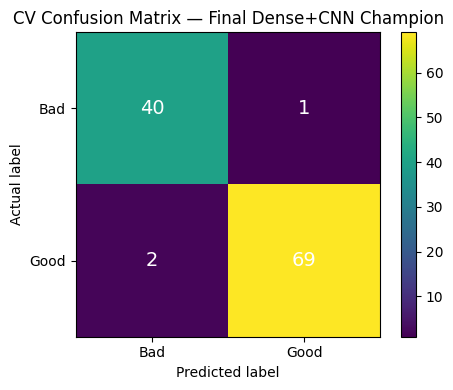

Saved: reporting/results/a13_dense_cnn_final_augmented_champion_confusion_matrix.png


In [ ]:
cv_tp = int(final_aug_fold_df["test_tp"].sum())
cv_fp = int(final_aug_fold_df["test_fp"].sum())
cv_tn = int(final_aug_fold_df["test_tn"].sum())
cv_fn = int(final_aug_fold_df["test_fn"].sum())

cm = np.array([[cv_tn, cv_fp], [cv_fn, cv_tp]])

print("Aggregated final augmented CV confusion matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm)
ax.set_title("CV Confusion Matrix — Final Dense+CNN Champion")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Bad", "Good"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Bad", "Good"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white", fontsize=14)
plt.colorbar(ax.images[0], ax=ax)
plt.tight_layout()

cm_path = output_dir / "a13_dense_cnn_final_augmented_champion_confusion_matrix.png"
fig.savefig(cm_path, dpi=150)
plt.show()
print("Saved:", cm_path)


### Training curves

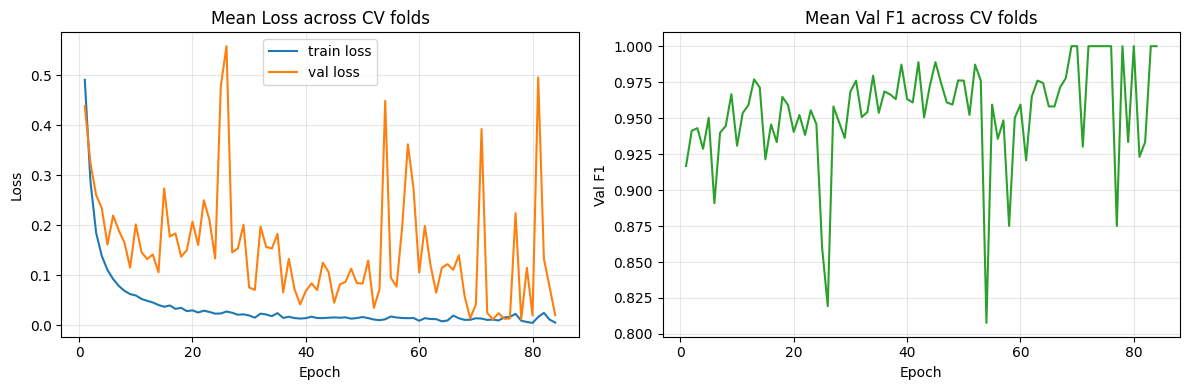

Saved: reporting/results/a13_dense_cnn_final_augmented_champion_training_curves.png


In [ ]:
mean_history = (
    final_aug_history_df
    .groupby("epoch")[["train_loss", "val_loss", "val_f1"]]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(mean_history["epoch"], mean_history["train_loss"], label="train loss")
axes[0].plot(mean_history["epoch"], mean_history["val_loss"],   label="val loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("Mean Loss across CV folds")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(mean_history["epoch"], mean_history["val_f1"], color="tab:green")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val F1")
axes[1].set_title("Mean Val F1 across CV folds")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
curves_path = output_dir / "a13_dense_cnn_final_augmented_champion_training_curves.png"
fig.savefig(curves_path, dpi=150)
plt.show()
print("Saved:", curves_path)


### Train final champion model on all data and save for integration

In [ ]:
def train_final_model_on_all_sequences(config, use_max_augmentation=True):
    all_ids    = sequence_ids_all.copy()
    all_labels = np.array([labels_lookup[sid] for sid in all_ids])

    train_ids, val_ids = train_test_split(
        all_ids,
        test_size=VALIDATION_SPLIT,
        random_state=RANDOM_SEED,
        stratify=all_labels if len(np.unique(all_labels)) == 2 else None,
    )

    final_scaler = fit_minmax_scaler_on_sequences(train_ids, sequence_dfs)

    X_train, y_train, _ = build_augmented_train_xy(
        train_ids, sequence_dfs, labels_lookup, final_scaler,
        config["seq_len"], config["feature_set"], use_max_augmentation)

    X_val, y_val, _ = build_xy_for_sequence_ids(
        val_ids, sequence_dfs, labels_lookup, final_scaler,
        config["seq_len"], config["feature_set"])

    n_features = X_train.shape[1]

    final_model = DenseCNNClassifier(
        n_features    = n_features,
        seq_len       = config["seq_len"],
        conv_channels = config["conv_channels"],
        kernel_size   = config["kernel_size"],
        stride        = config.get("stride", 1),
        dense_dims    = config["dense_dims"],
        dropout       = config["dropout"],
    ).to(DEVICE)

    train_loader = make_loader(X_train, y_train, config["batch_size"], True)
    val_loader   = make_loader(X_val,   y_val,   config["batch_size"], False)

    final_model, final_history_df, final_train_summary = train_one_model(
        final_model, train_loader, val_loader,
        config["learning_rate"], config["epochs"], config["patience"])

    train_m = evaluate_model(final_model, train_loader, config["threshold"])
    val_m   = evaluate_model(final_model, val_loader,   config["threshold"])

    final_info = {
        "n_features":                        n_features,
        "n_parameters":                      count_trainable_parameters(final_model),
        "n_train_original_sequences":        len(train_ids),
        "n_train_samples_after_augmentation": len(X_train),
        "n_val_sequences":                   len(val_ids),
        "best_val_loss":                     final_train_summary["best_val_loss"],
        "best_epoch":                        final_train_summary["best_epoch"],
        "epochs_ran":                        final_train_summary["epochs_ran"],
        "train_accuracy": train_m["accuracy"], "train_f1": train_m["f1"], "train_auc": train_m["auc"],
        "val_accuracy":   val_m["accuracy"],   "val_f1":   val_m["f1"],   "val_auc":   val_m["auc"],
    }

    return final_model, final_scaler, final_history_df, final_info, train_ids, val_ids


final_model, final_scaler, final_history_df, final_info, final_train_ids, final_val_ids = \
    train_final_model_on_all_sequences(config=CHAMPION_CONFIG, use_max_augmentation=True)

print("Final model info:")
print(json.dumps(final_info, indent=2))


Final model info:
{
  "n_features": 38,
  "n_parameters": 945,
  "n_train_original_sequences": 100,
  "n_train_samples_after_augmentation": 3200,
  "n_val_sequences": 12,
  "best_val_loss": 2.4834575015120208e-05,
  "best_epoch": 54,
  "epochs_ran": 69,
  "train_accuracy": 1.0,
  "train_f1": 1.0,
  "train_auc": 1.0,
  "val_accuracy": 1.0,
  "val_f1": 1.0,
  "val_auc": 1.0
}


### Log final champion model to MLFlow

In [ ]:
final_model_path   = artifact_dir / "a13_final_dense_cnn_champion_model.pt"
final_scaler_path  = artifact_dir / "a13_final_dense_cnn_champion_minmax_scaler.joblib"
final_config_path  = artifact_dir / "a13_final_dense_cnn_champion_config.json"
final_history_path = output_dir   / "a13_final_dense_cnn_champion_training_history.csv"

torch.save(final_model.state_dict(), final_model_path)
joblib.dump(final_scaler, final_scaler_path)
final_history_df.to_csv(final_history_path, index=False)

final_config_to_save = {
    **{k: (list(v) if isinstance(v, tuple) else v) for k, v in CHAMPION_CONFIG.items()},
    "model_family":       "Dense+CNN",
    "n_features":         final_info["n_features"],
    "n_parameters":       final_info["n_parameters"],
    "coord_cols":         COORD_COLS,
    "joints_13":          JOINTS_13,
    "normalization":      "MinMaxScaler fit on training data only",
    "augmentation":       "max cascade augmentation for final champion training",
}
with open(final_config_path, "w") as f:
    json.dump(final_config_to_save, f, indent=2)

with mlflow.start_run(run_name=f"a13_logged_final_dense_cnn_champion_{CHAMPION_CONFIG['name']}"):
    mlflow.log_param("problem",         "B")
    mlflow.log_param("input_type",      "MoveNet_2D")
    mlflow.log_param("model_family",    "Dense+CNN")
    mlflow.log_param("task",            "good_vs_bad_sequence_classification")
    mlflow.log_params({k: str(v) for k, v in CHAMPION_CONFIG.items()})
    mlflow.log_param("n_features",  final_info["n_features"])
    mlflow.log_param("n_parameters", final_info["n_parameters"])
    mlflow.log_param("use_max_augmentation", True)

    for key, value in final_info.items():
        try:
            mlflow.log_metric(key, float(value))
        except (TypeError, ValueError):
            pass

    mlflow.log_artifact(str(final_model_path))
    mlflow.log_artifact(str(final_scaler_path))
    mlflow.log_artifact(str(final_config_path))
    mlflow.log_artifact(str(final_history_path))
    mlflow.pytorch.log_model(final_model, artifact_path="model")

print("Final champion logged to MLflow.")


2026/05/12 12:37:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/12 12:37:29 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is to set 'export_model' to True to save the pytorch model using the safe graph model format.


🏃 View run a13_logged_final_dense_cnn_champion_cnn_8_k3_dist_drop020 at: https://172.27.62.170:5001/#/experiments/32/runs/430ce6de27ff4ec7bb810fc3633e787f
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/32
Final champion logged to MLflow.


### Prediction helper for practical usefulness check

In [ ]:
def predict_good_bad_sequence(model, scaler, sequence_df, config, threshold=THRESHOLD):
    model.eval()

    x = sequence_to_cnn_matrix(
        sequence_df, scaler, config["seq_len"], config["feature_set"])

    x_tensor = torch.tensor(x[np.newaxis], dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        prob_good = float(torch.sigmoid(model(x_tensor)).detach().cpu().numpy()[0])

    pred_label = int(prob_good >= threshold)
    return {
        "prob_good":  prob_good,
        "pred_label": pred_label,
        "pred_class": "good" if pred_label == 1 else "bad",
    }


example_sid        = sequence_ids_all[0]
example_df         = sequence_dfs[example_sid]
example_true_label = labels_lookup[example_sid]

result = predict_good_bad_sequence(
    model=final_model, scaler=final_scaler,
    sequence_df=example_df, config=CHAMPION_CONFIG,
    threshold=CHAMPION_CONFIG["threshold"],
)

print("Example sequence:", example_sid)
print("True class:", "good" if example_true_label == 1 else "bad")
print("Prediction:", result)


Example sequence: A1
True class: good
Prediction: {'prob_good': 0.9981243014335632, 'pred_label': 1, 'pred_class': 'good'}
